In [1]:
# Install Packages
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as stats

In [2]:
# Load in tables
athletes = pd.read_csv("../data/athlete_events.csv")
city_coords = pd.read_csv("../data/city_coords.csv")
country_coords = pd.read_csv("../data/country_coords.csv")
noc_regions = pd.read_csv("../data/noc_regions.csv")

In [3]:
# Merge all original tables
df = athletes.merge(
    noc_regions,
    on="NOC",
    how="left"
)
df = df.merge(
    country_coords,
    left_on="region",
    right_on="Country",
    how="left"
)
df = df.rename(columns={
    "Latitude": "country_lat",
    "Longitude": "country_lon"
})
df = df.merge(
    city_coords,
    on="City",
    how="left"
)
df = df.rename(columns={
    "Latitude": "host_lat",
    "Longitude": "host_lon"
})

In [4]:
# Calculate approximate distance between country and host city
df["distance_to_host"] = np.sqrt(
    (69 * (df["country_lat"] - df["host_lat"]))**2 +
    (69 * np.cos(np.radians(df["host_lat"])) * (df["country_lon"] - df["host_lon"]))**2
)
# df.head()

In [5]:
# set weighted medal score
df["Medal"] = df["Medal"].fillna("None")
df["medal_score"] = df["Medal"].map({
    "Gold": 5,
    "Silver": 3,
    "Bronze": 1,
    "None": 0
})
# df.head()

In [6]:
# Group by NOC, medal, games, and event to remove duplicate entries for team sports
event_results = (
    df.groupby(["NOC","Games","Event"], as_index=False)
    .agg(
        Medal=("Medal","first"),
        medal_score=("medal_score","first"),
        distance_to_host=("distance_to_host","first")
    )
)
event_results["won_medal"] = event_results["Medal"] != "None"
# print(len(event_results))
# event_results.head()

In [7]:
country_overall = (
    event_results
    .groupby(["NOC"], as_index=False)
    .agg(
        medals=("won_medal", "sum"),
        medal_score=("medal_score", "sum"),
        events_participated=("Event", "size"),
        distance_to_host=("distance_to_host", "first")
    )
)
country_overall["avg_medals_per_event"] = (
    country_overall["medals"] /
    country_overall["events_participated"]
)

country_overall["avg_score_per_event"] = (
    country_overall["medal_score"] /
    country_overall["events_participated"]
)

# country_overall.head()

In [8]:
country_games = (
    event_results
    .groupby(["NOC","Games"], as_index=False)
    .agg(
        medals=("won_medal","sum"),
        medal_score=("medal_score","sum"),
        events_participated=("Event","size"),
        distance_to_host=("distance_to_host","first")
    )
)

country_games["medals_per_event"] = (
    country_games["medals"] /
    country_games["events_participated"]
)

country_games["score_per_event"] = (
    country_games["medal_score"] /
    country_games["events_participated"]
)
country_games = country_games.merge(
    country_overall[["NOC","avg_medals_per_event","avg_score_per_event"]],
    on="NOC",
    how="left"
)
# country_games.head()

In [9]:
country_games["pct_medals_over_avg"] = (
    (country_games["medals_per_event"] - country_games["avg_medals_per_event"]) /
    country_games["avg_medals_per_event"]
)
country_games["pct_score_over_avg"] = (
    (country_games["score_per_event"] - country_games["avg_score_per_event"]) /
    country_games["avg_score_per_event"]
)
# country_games.head(20)

In [ ]:
# Filter for recent games
recent_games = country_games[
    country_games["Games"].isin(["2016 Summer", "2014 Winter", "2012 Summer", "2010 Winter", "2008 Summer"])
]

In [11]:
filtered_games = recent_games[recent_games["events_participated"] >= 5]
filtered_games = recent_games[recent_games["avg_medals_per_event"] > 0]
# filtered_games.head()

In [14]:
plot_data = filtered_games[
    filtered_games["pct_medals_over_avg"].abs() < 3
].copy()

plot_data["pct_medals_over_avg"] *= 100

plot_data = plot_data[
    plot_data["pct_medals_over_avg"] > -100
]

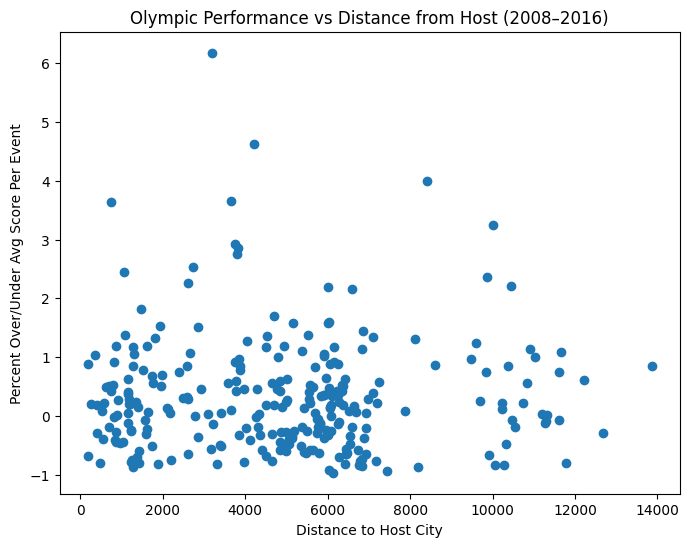

In [23]:
plt.figure(figsize=(8,6))

plt.scatter(
    plot_data["distance_to_host"],
    plot_data["pct_score_over_avg"]
)

plt.xlabel("Distance to Host City")
plt.ylabel("Percent Over/Under Avg Score Per Event")
plt.title("Olympic Performance vs Distance from Host (2008–2016)")

plt.show()

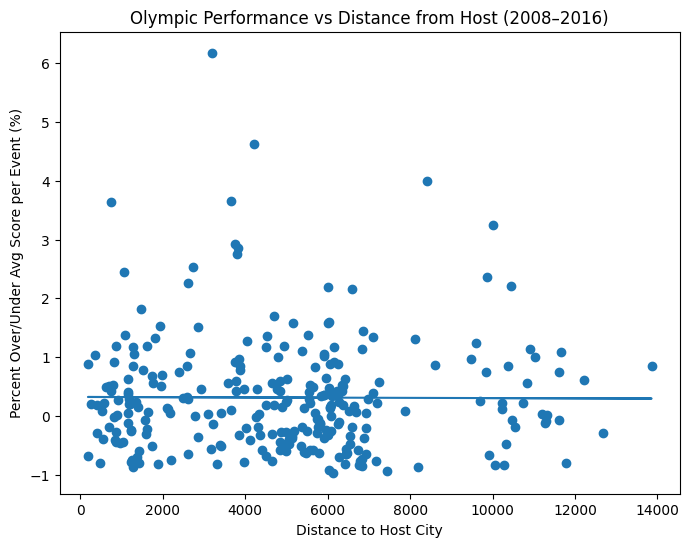

: 

In [ ]:
x = plot_data["distance_to_host"]
y = plot_data["pct_score_over_avg"]

m, b = np.polyfit(x, y, 1)

plt.figure(figsize=(8,6))

plt.scatter(x, y)

plt.plot(x, m*x + b)

plt.xlabel("Distance to Host City")
plt.ylabel("Percent Over/Under Avg Score per Event (%)")
plt.title("Olympic Performance vs Distance from Host (2008–2016)")

plt.show()

In [17]:
r = np.corrcoef(x, y)[0,1]
print("Correlation:", r)

Correlation: -0.0026237295836002423


In [20]:
host_map = {
    "2016 Summer": "BRA",
    "2014 Winter": "RUS",
    "2012 Summer": "GBR",
    "2010 Winter": "CAN",
    "2008 Summer": "CHN"
}

host_rows = filtered_games[
    filtered_games.apply(lambda r: host_map.get(r["Games"]) == r["NOC"], axis=1)
]

print(host_rows)

      NOC        Games  medals  medal_score  events_participated  \
511   BRA  2016 Summer      14           48                  222   
638   CAN  2010 Winter      15           59                   83   
734   CHN  2008 Summer      65          239                  257   
1309  GBR  2012 Summer      56          188                  249   
3034  RUS  2014 Winter      17           49                   94   

      distance_to_host  medals_per_event  score_per_event  \
511        1165.412983          0.063063         0.216216   
638        1465.919873          0.180723         0.710843   
734         692.163508          0.252918         0.929961   
1309        189.872123          0.224900         0.755020   
3034       3216.750532          0.180851         0.521277   

      avg_medals_per_event  avg_score_per_event  pct_medals_over_avg  \
511               0.065311             0.154036            -0.034421   
638               0.093176             0.251576             0.939582   
734     